# Exploratory Data Analysis (EDA): Target (tma_mdpl)

Fokus EDA:
1. **Distribusi & outlier per pos** - Mencari lonjakan liar (outliers) dan mencegah model belajar dari noise sensor.
2. **Trend musiman (musim hujan vs kemarau)** - Menentukan apakah perlu fitur seasonal/cyclical (bulan, hari-dalam-tahun).
3. **Autokorelasi (ACF/PACF) per pos** - Menentukan berapa banyak lag yang relevan untuk fitur autokorelasi.
4. **Perbandingan level TMA antar pos yang searah sungai** - Konfirmasi hubungan hulu-hilir (validasi fitur upstream).

In [49]:
import os
os.makedirs('output_eda', exist_ok=True)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')
plt.style.use('ggplot')

## Load Data
Kita memuat data train dan mengubah kolom `datetime`.

In [50]:
# Load data train
df_train = pd.read_csv('../train.csv')
df_train['datetime'] = pd.to_datetime(df_train['datetime'])
df_train.sort_values(by=['nama_pos', 'datetime'], inplace=True)

print("Shape data train:", df_train.shape)
display(df_train.head())

Shape data train: (84396, 3)


,datetime,nama_pos,tma_mdpl
0,2023-01-01 06:00:00,Arjowinangun - Pacitan,1.30
1,2023-01-01 12:00:00,Arjowinangun - Pacitan,1.20
2,2023-01-01 18:00:00,Arjowinangun - Pacitan,1.50
3,2023-01-02 06:00:00,Arjowinangun - Pacitan,1.45
4,2023-01-02 12:00:00,Arjowinangun - Pacitan,1.25


## 1. Distribusi & Outlier per Pos
Kita melihat distribusi `tma_mdpl` menggunakan boxplot untuk memvisualisasikan adanya lonjakan liar dari sensor.

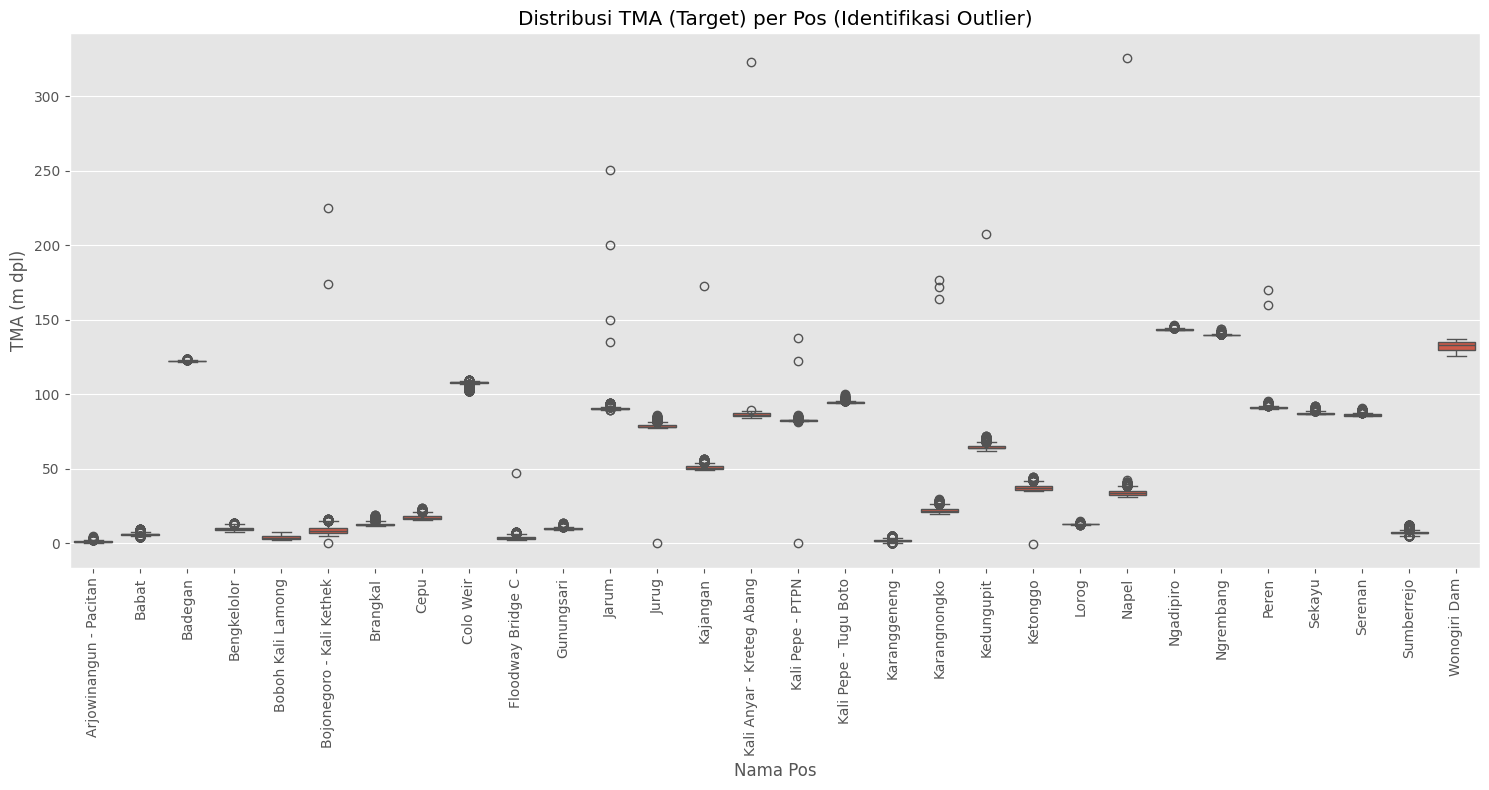

In [51]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=df_train, x='nama_pos', y='tma_mdpl')
plt.xticks(rotation=90)
plt.title('Distribusi TMA (Target) per Pos (Identifikasi Outlier)')
plt.ylabel('TMA (m dpl)')
plt.xlabel('Nama Pos')
plt.tight_layout()
plt.savefig('output_eda/plot_1.png', bbox_inches='tight', dpi=300)
plt.show()

Kita juga mengecek time-series mentah untuk beberapa pos, untuk melihat apakah outlier tersebut hanyalah *noise* (spike sesaat) atau memang pergerakan banjir asli.

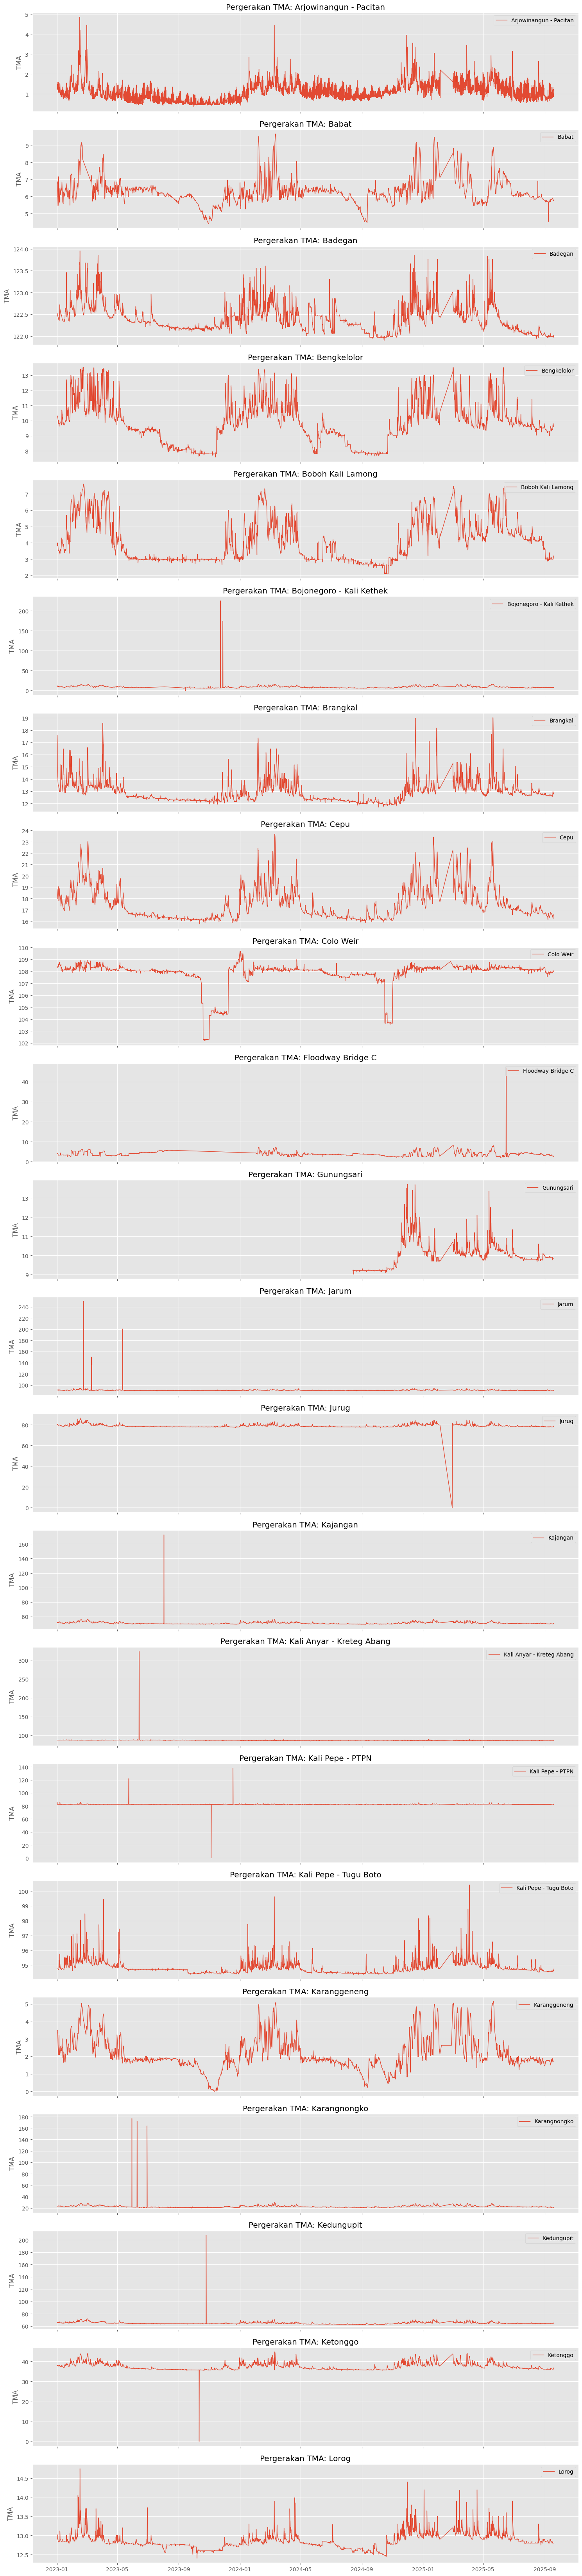

In [52]:
# Plot time series untuk 4 pos sampel
sample_pos = df_train['nama_pos'].unique()[:int(0.75 * len(df_train['nama_pos'].unique()))]
fig, axes = plt.subplots(len(sample_pos), 1, figsize=(15, 3*len(sample_pos)), sharex=True)

for i, pos in enumerate(sample_pos):
    data_pos = df_train[df_train['nama_pos'] == pos]
    axes[i].plot(data_pos['datetime'], data_pos['tma_mdpl'], label=pos, linewidth=1)
    axes[i].set_title(f'Pergerakan TMA: {pos}')
    axes[i].set_ylabel('TMA')
    axes[i].legend(loc='upper right')
    
plt.tight_layout()
plt.savefig('output_eda/plot_2.png', bbox_inches='tight', dpi=300)
plt.show()

## 2. Trend Musiman (Musim Hujan vs Kemarau)
Ekstraksi bulan untuk mengecek apakah ada pola berulang (misal tinggi di akhir/awal tahun).

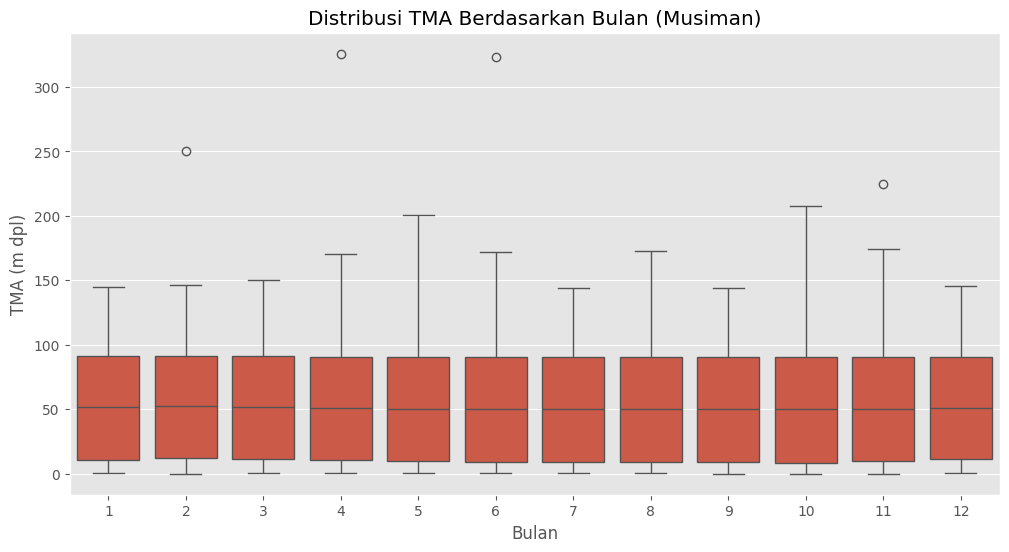

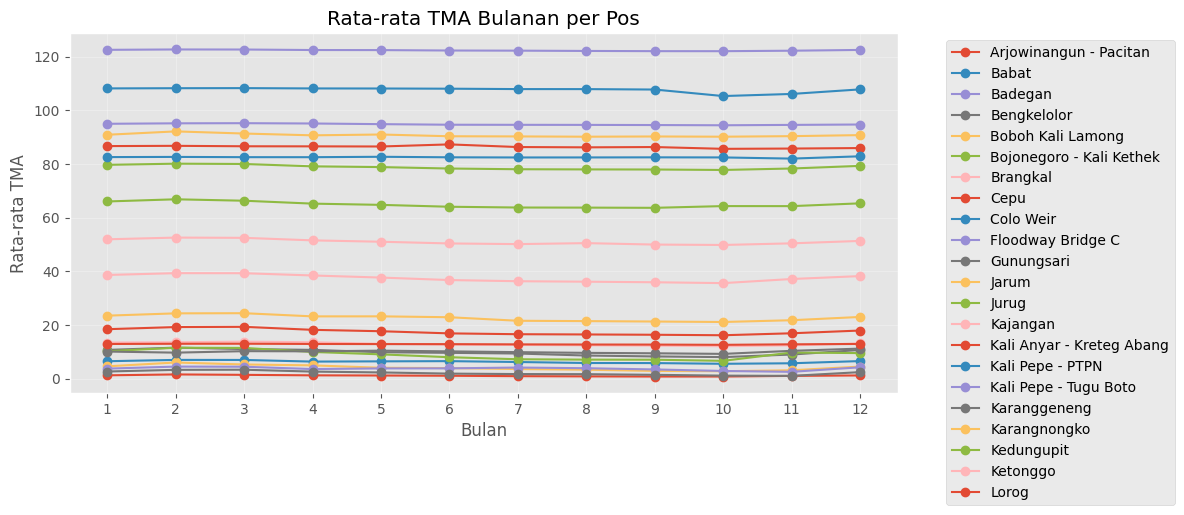

In [53]:
df_train['bulan'] = df_train['datetime'].dt.month

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_train, x='bulan', y='tma_mdpl')
plt.title('Distribusi TMA Berdasarkan Bulan (Musiman)')
plt.xlabel('Bulan')
plt.ylabel('TMA (m dpl)')
plt.savefig('output_eda/plot_3.png', bbox_inches='tight', dpi=300)
plt.show()

# Rata-rata per bulan untuk beberapa pos contoh
monthly_avg = df_train.groupby(['nama_pos', 'bulan'])['tma_mdpl'].mean().unstack(level=0)
monthly_avg[sample_pos].plot(figsize=(12, 5), marker='o')
plt.title('Rata-rata TMA Bulanan per Pos')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata TMA')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('output_eda/plot_4.png', bbox_inches='tight', dpi=300)
plt.show()

## 3. Autokorelasi (ACF/PACF) per Pos
ACF/PACF digunakan untuk melihat korelasi TMA dengan nilai sebelumnya (lag). Jika lag tinggi di ACF, berarti respon sungai lambat (kemungkinan sungai besar). Membantu menentukan batas window size/lags untuk features.

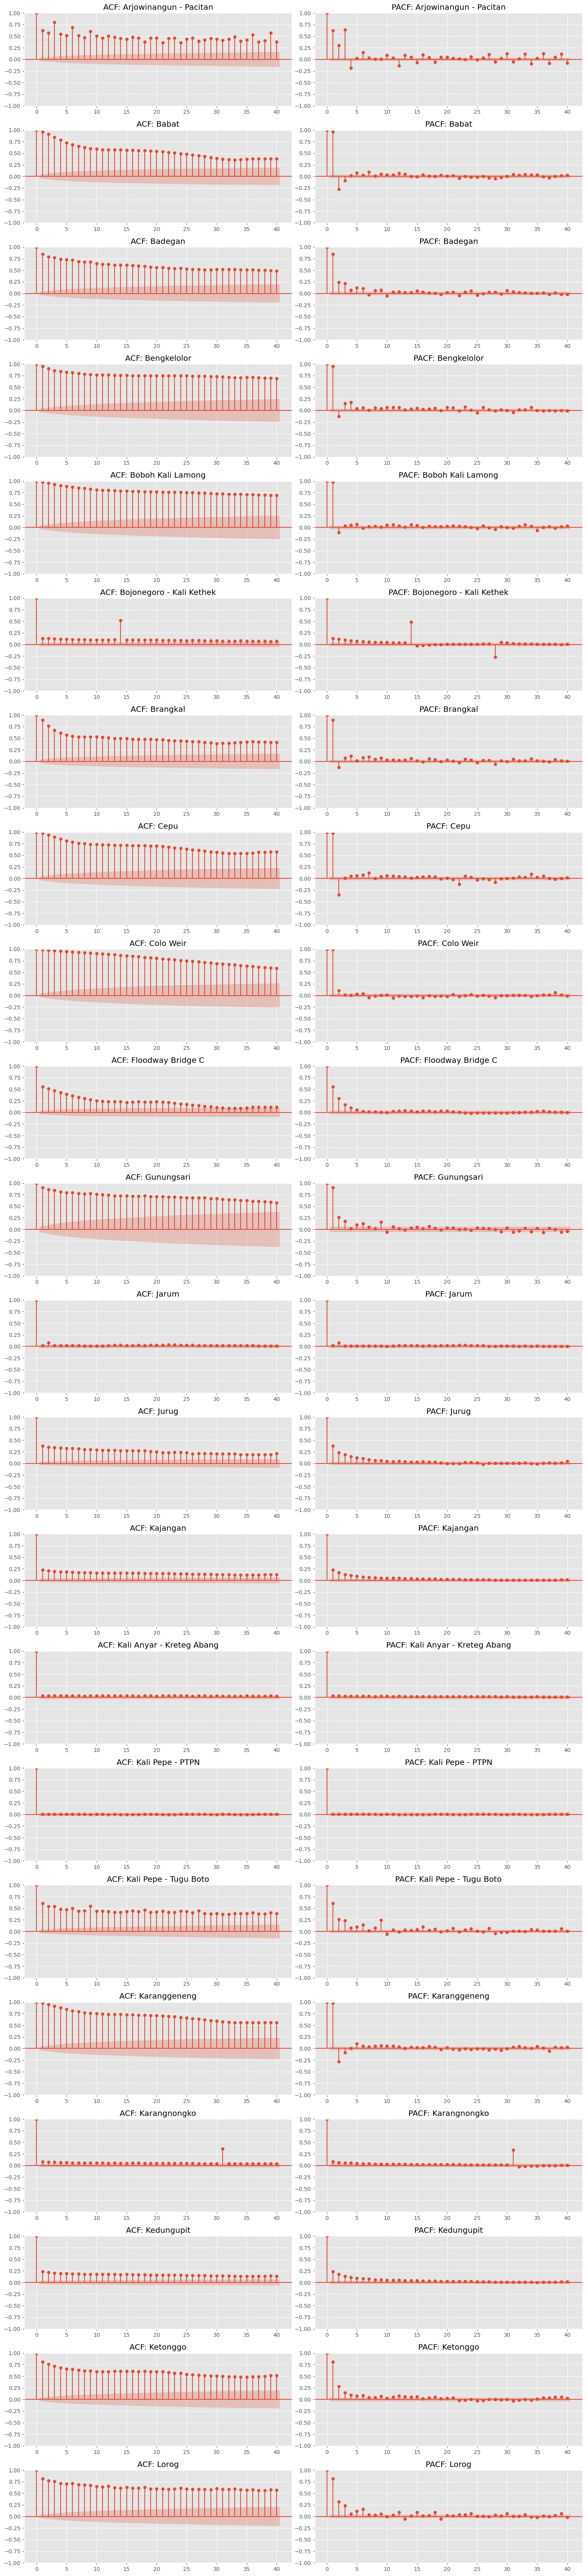

In [54]:
lags_to_check = 40  # lag steps
fig, axes = plt.subplots(len(sample_pos), 2, figsize=(15, 3*len(sample_pos)))

for i, pos in enumerate(sample_pos):
    data_pos = df_train[df_train['nama_pos'] == pos].set_index('datetime')['tma_mdpl']
    data_pos = data_pos.ffill().dropna()
    
    if len(data_pos) > lags_to_check:
        plot_acf(data_pos, lags=lags_to_check, ax=axes[i, 0], title=f'ACF: {pos}')
        plot_pacf(data_pos, lags=lags_to_check, ax=axes[i, 1], title=f'PACF: {pos}')

plt.tight_layout()
plt.savefig('output_eda/plot_5.png', bbox_inches='tight', dpi=300)
plt.show()

## 4. Perbandingan Level TMA antar Pos yang Searah Sungai
Mengecek korelasi antar pos. Pos hulu dan hilir yang berada di sungai yang sama harusnya punya korelasi yang cukup terlihat.

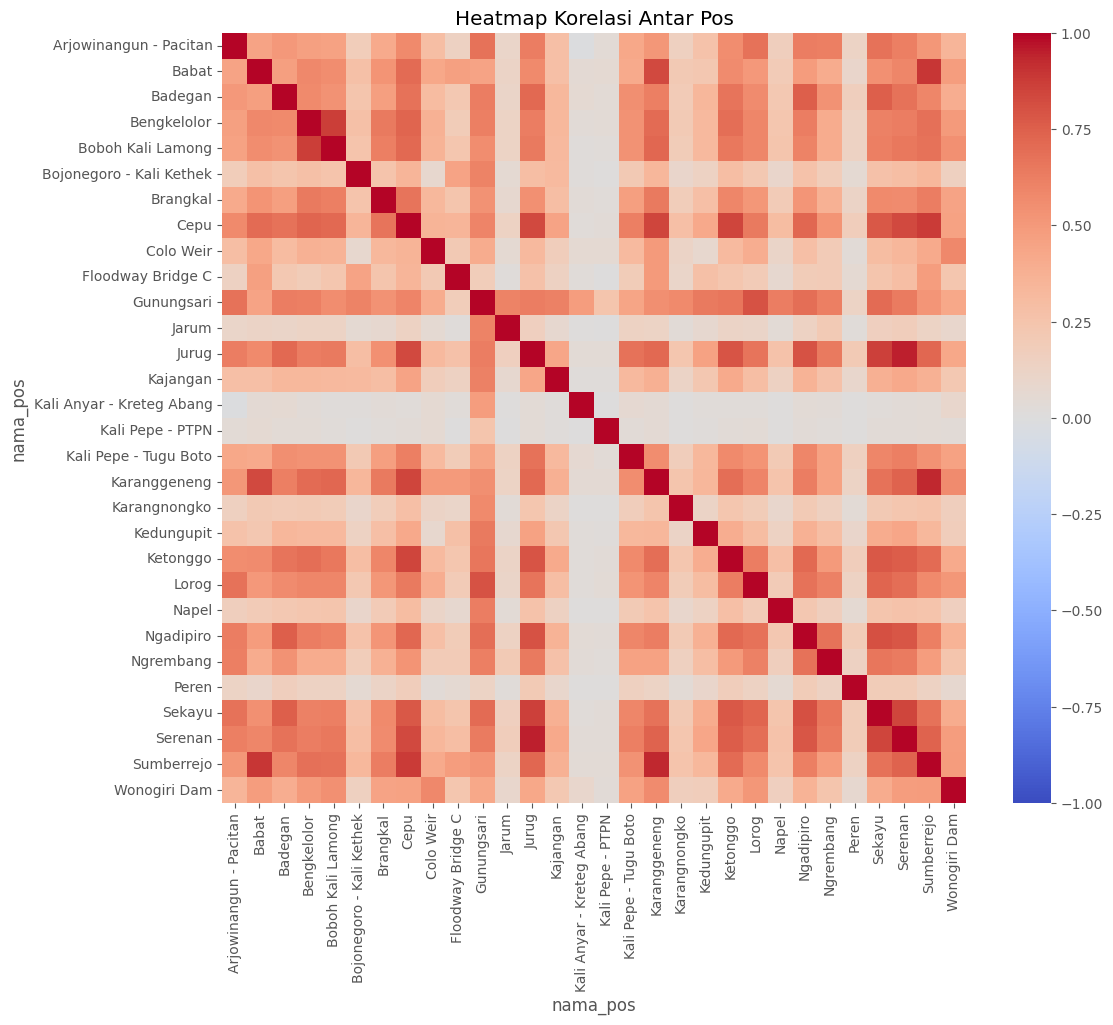

In [55]:
# Pivot agar baris = datetime, kolom = pos
df_pivot = df_train.pivot_table(index='datetime', columns='nama_pos', values='tma_mdpl')

# Korelasi matriks (Spearman seringkali lebih baik untuk sinyal rank / non-linear, tapi Pearson oke sebagai awalan)
corr_matrix = df_pivot.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Antar Pos')
plt.savefig('output_eda/plot_6.png', bbox_inches='tight', dpi=300)
plt.show()

Visualisasi pos dengan korelasi tertinggi (asumsi hulu-hilir kuat).

In [56]:
corr_pairs = corr_matrix.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 0.999]  # Drop self-correlation (1.0)

if len(corr_pairs) > 0:
    pos1, pos2 = corr_pairs.index[0]
    print(f"-> Pasangan pos paling berkorelasi: {pos1} & {pos2} ({corr_pairs.iloc[0]:.3f})")
    
    # Kita tampilkan plot untuk 1000 data point pertama yang tidak kosong pada keduanya
    subset = df_pivot[[pos1, pos2]].dropna().iloc[:int(0.75 * len(df_pivot[[pos1, pos2]].dropna()))]
    
    plt.figure(figsize=(15, 5))
    plt.plot(subset.index, subset[pos1], label=pos1, alpha=0.8)
    plt.plot(subset.index, subset[pos2], label=pos2, alpha=0.8)
    plt.title(f'Overlay Time-Series: {pos1} vs {pos2}')
    plt.ylabel('TMA')
    plt.xlabel('Waktu')
    plt.legend()
plt.savefig('output_eda/plot_7.png', bbox_inches='tight', dpi=300)
    plt.show()
else:
    print("Belum cukup data untuk plot korelasi pasangan.")

IndentationError: unexpected indent (414544528.py, line 19)

---
## Exploratory Data Analysis (EDA): Fitur Eksogen (`data_lingkungan.csv`)

Fokus EDA:
1. **Korelasi rainfall_mm vs rainfall_openmeteo_mm** - Mengetahui apakah dua fitur curah hujan ini saling melengkapi atau redundan.
2. **Distribusi & missing value per fitur cuaca** - Mengecek pola missing value dan dominasi nol pada data cuaca.
3. **Korelasi antar 4 layer soil moisture** - Evaluasi kemungkinan redundansi sehingga dapat disederhanakan.
4. **Resolusi temporal mismatch & Lag/lead relationship** - Mengatasi beda resolusi (per jam vs per 6 jam) dengan agregasi yang sesuai lalu melihat *response time* hujan ke target.
5. **RMM1/RMM2/MJO/Nino3.4** - Mengecek granularity fitur cuaca makro (slow-varying features) agar tidak menyebabkan overfitting ke pola lambat.

In [ ]:
# Load data lingkungan
df_env = pd.read_csv('../data_pendukung/data_lingkungan.csv')
df_env['datetime'] = pd.to_datetime(df_env['datetime'])
df_env.sort_values(by=['nama_pos', 'datetime'], inplace=True)
print("Shape data lingkungan:", df_env.shape)
display(df_env.head(3))

Shape data lingkungan: (888480, 27)


,datetime,nama_pos,rainfall_mm,humidity_pct,wind_direction_deg,dew_point_c,cloud_cover_pct,temperature_c,wind_speed_kmh,rainfall_openmeteo_mm,...,pressure_msl_hpa,built_surface_m2,landcover_class,landcover_name,rmm1,rmm2,mjo_phase,mjo_amplitude,mjo_active,nino_34
0,2023-01-01 00:00:00,Arjowinangun - Pacitan,0.0,89,346,22.9,100,24.8,10.7,0.0,...,1010.2,2419.0,10,Tree cover,-0.092299,1.277599,7.0,1.280929,1.0,-0.72
1,2023-01-01 01:00:00,Arjowinangun - Pacitan,0.0,88,350,22.7,100,24.9,12.8,0.0,...,1009.6,2419.0,10,Tree cover,-0.092299,1.277599,7.0,1.280929,1.0,-0.72
2,2023-01-01 02:00:00,Arjowinangun - Pacitan,0.0,86,349,22.5,100,25.1,13.2,0.0,...,1008.7,2419.0,10,Tree cover,-0.092299,1.277599,7.0,1.280929,1.0,-0.72


### 1. Korelasi rainfall_mm vs rainfall_openmeteo_mm

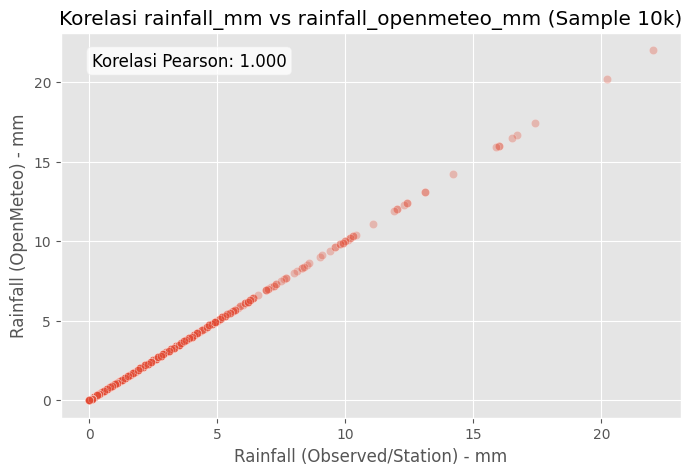

Persentase curah hujan 0 (Observed) : 71.40%
Persentase curah hujan 0 (OpenMeteo): 71.40%


In [ ]:
# Scatter plot dan korelasi antara rainfall observed dan openmeteo
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_env.sample(frac=0.75, random_state=42), x='rainfall_mm', y='rainfall_openmeteo_mm', alpha=0.3)
plt.title('Korelasi rainfall_mm vs rainfall_openmeteo_mm (Sample 10k)')
plt.xlabel('Rainfall (Observed/Station) - mm')
plt.ylabel('Rainfall (OpenMeteo) - mm')

corr_rain = df_env['rainfall_mm'].corr(df_env['rainfall_openmeteo_mm'])
plt.text(0.05, 0.95, f'Korelasi Pearson: {corr_rain:.3f}', transform=plt.gca().transAxes, fontsize=12,
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.savefig('output_eda/plot_8.png', bbox_inches='tight', dpi=300)
plt.show()

# Cek persentase nol
pct_zero_obs = (df_env['rainfall_mm'] == 0).mean() * 100
pct_zero_om = (df_env['rainfall_openmeteo_mm'] == 0).mean() * 100
print(f"Persentase curah hujan 0 (Observed) : {pct_zero_obs:.2f}%")
print(f"Persentase curah hujan 0 (OpenMeteo): {pct_zero_om:.2f}%")

### 2. Distribusi & Missing Value per Fitur Cuaca

Missing Value pada Fitur Cuaca:


,Missing,Percentage (%)
rainfall_mm,0,0.0
humidity_pct,0,0.0
temperature_c,0,0.0
wind_speed_kmh,0,0.0
solar_radiation_mj_m2,0,0.0


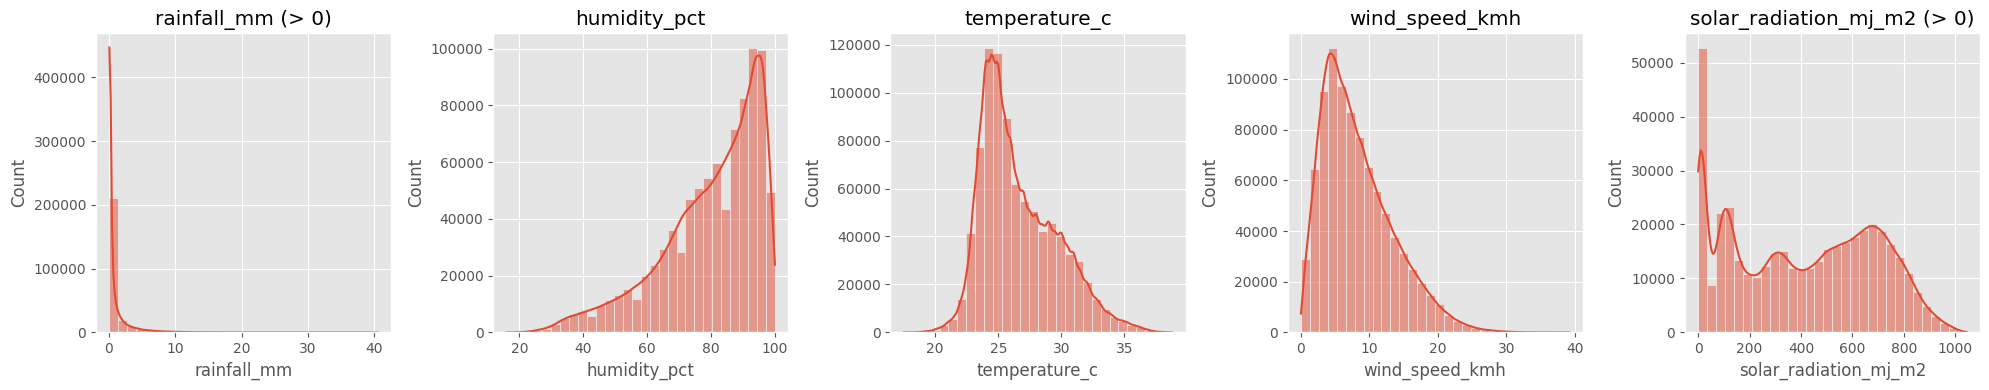

In [ ]:
weather_features = ['rainfall_mm', 'humidity_pct', 'temperature_c', 'wind_speed_kmh', 'solar_radiation_mj_m2']

# Cek Missing Values
missing = df_env[weather_features].isnull().sum()
missing_pct = (missing / len(df_env)) * 100
print("Missing Value pada Fitur Cuaca:")
display(pd.DataFrame({'Missing': missing, 'Percentage (%)': missing_pct}))

# Plot Distribusi (untuk nilai yang non-zero agar pola selain nol terlihat)
fig, axes = plt.subplots(1, len(weather_features), figsize=(20, 4))
for i, feat in enumerate(weather_features):
    if feat in ['rainfall_mm', 'solar_radiation_mj_m2']:
        data_to_plot = df_env[df_env[feat] > 0][feat].dropna()
        axes[i].set_title(f'{feat} (> 0)')
    else:
        data_to_plot = df_env[feat].dropna()
        axes[i].set_title(feat)
    
    sns.histplot(data_to_plot, bins=30, ax=axes[i], kde=True)

plt.tight_layout()
plt.savefig('output_eda/plot_9.png', bbox_inches='tight', dpi=300)
plt.show()

### 3. Korelasi antar 4 Layer Soil Moisture

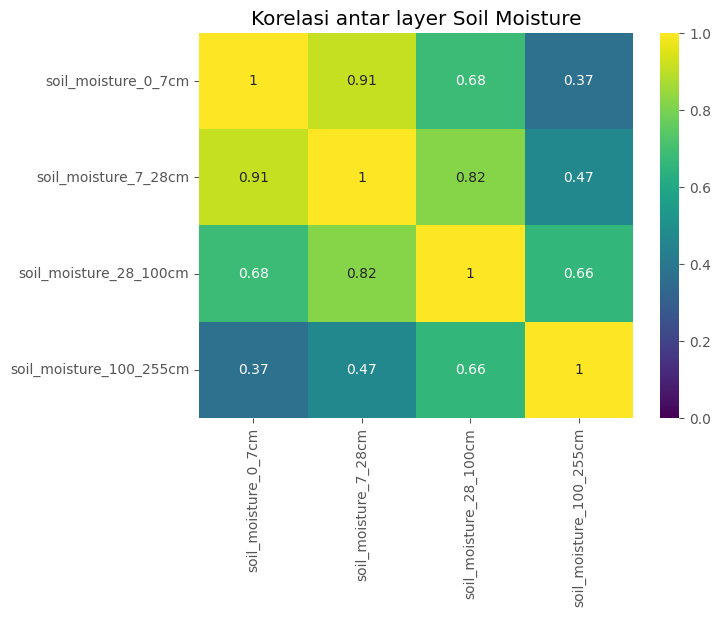

In [ ]:
soil_features = ['soil_moisture_0_7cm', 'soil_moisture_7_28cm', 'soil_moisture_28_100cm', 'soil_moisture_100_255cm']

soil_corr = df_env[soil_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(soil_corr, annot=True, cmap='viridis', vmin=0, vmax=1)
plt.title('Korelasi antar layer Soil Moisture')
plt.savefig('output_eda/plot_10.png', bbox_inches='tight', dpi=300)
plt.show()

# Kesimpulan sementara: Jika korelasi antar layer atas sangat tinggi, kita bisa mempertimbangkan untuk mengambil rata-ratanya, atau sekadar memilih layer yang paling representatif saja (misal layer teratas dan terbawah) daripada memasukkan keempat layer.

### 4 & 5. Resolusi Temporal & Lag/Lead Relationship Rainfall vs TMA
Data `data_lingkungan.csv` beresolusi per 1 jam, target `tma_mdpl` per 6 jam (00, 06, 12, 18). Kita agregasi curah hujan dengan `sum` (akumulasi selama 6 jam), lalu gabungkan ke data train untuk melihat *response time* TMA dari kejadian hujan.

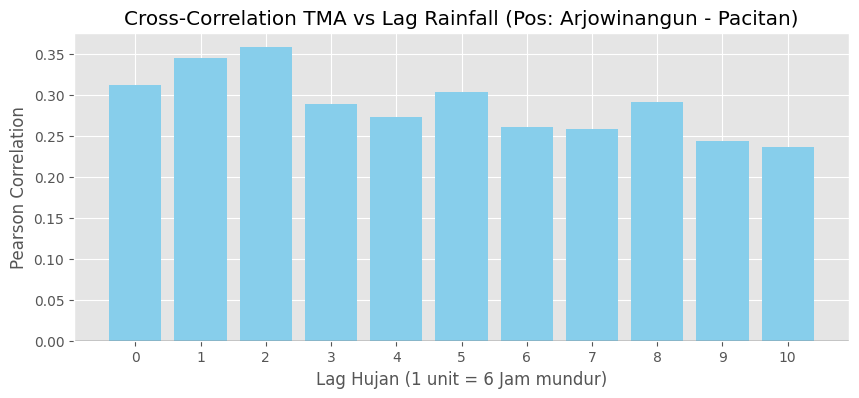

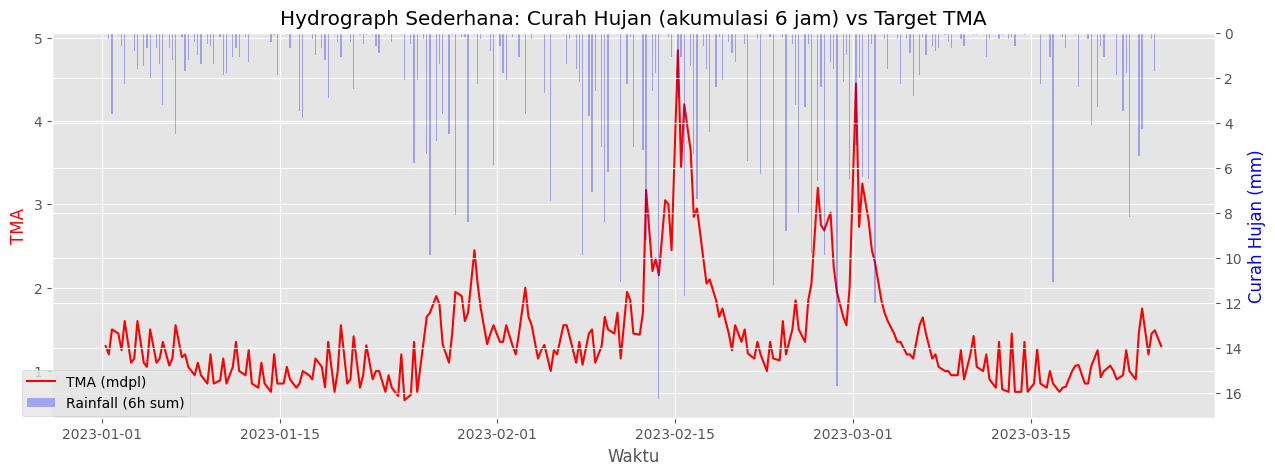

In [ ]:
# Gunakan 1 pos sebagai sampel
pos_example = df_train['nama_pos'].unique()[0]
env_pos = df_env[df_env['nama_pos'] == pos_example].copy()
env_pos.set_index('datetime', inplace=True)

# Resample menjadi 6 jam (00, 06, 12, 18)
# Note: Karena data target ada di 06:00, 12:00, dll, resample '6h' mensejajarkan window 6 jam. Label=right agar hujan dari jam 00-06 masuk ke index 06:00
env_pos_6h = env_pos.resample('6h', label='right').agg({
    'rainfall_mm': 'sum',
    'soil_moisture_0_7cm': 'mean'
})

# Gabung dengan target
train_pos = df_train[df_train['nama_pos'] == pos_example].set_index('datetime')
merged_pos = train_pos.join(env_pos_6h, how='inner')

# Cross-Correlation (Korelasi target TMA dengan Lag Curah Hujan)
lags = range(0, 11)
corr_with_lags = []
for lag in lags:
    shifted_rain = merged_pos['rainfall_mm'].shift(lag)
    corr = merged_pos['tma_mdpl'].corr(shifted_rain)
    corr_with_lags.append(corr)

plt.figure(figsize=(10, 4))
plt.bar(lags, corr_with_lags, color='skyblue')
plt.axhline(0, color='black', lw=1)
plt.title(f'Cross-Correlation TMA vs Lag Rainfall (Pos: {pos_example})')
plt.xlabel('Lag Hujan (1 unit = 6 Jam mundur)')
plt.ylabel('Pearson Correlation')
plt.xticks(lags)
plt.savefig('output_eda/plot_11.png', bbox_inches='tight', dpi=300)
plt.show()

# Visualisasi hydrograph sederhana (Hujan vs TMA)
fig, ax1 = plt.subplots(figsize=(15, 5))
subset = merged_pos.iloc[:int(0.75 * len(merged_pos))] # Gunakan 75% data
ax1.plot(subset.index, subset['tma_mdpl'], color='red', label='TMA (mdpl)')
ax1.set_ylabel('TMA', color='red')
ax1.set_xlabel('Waktu')

ax2 = ax1.twinx()
ax2.bar(subset.index, subset['rainfall_mm'], color='blue', alpha=0.3, width=0.1, label='Rainfall (6h sum)')
ax2.set_ylabel('Curah Hujan (mm)', color='blue')
ax2.invert_yaxis() # Supaya mirip standar plot hidrografik

plt.title('Hydrograph Sederhana: Curah Hujan (akumulasi 6 jam) vs Target TMA')
fig.legend(loc="lower left", bbox_to_anchor=(0.1, 0.1))
plt.savefig('output_eda/plot_12.png', bbox_inches='tight', dpi=300)
plt.show()

### 6. RMM1/RMM2/MJO/Nino3.4 — Cek Granularity Temporal
Mengecek laju perubahan fitur indikator global agar tidak terjadi overfitting pada memori jangka panjang tanpa dasar logika fisik.

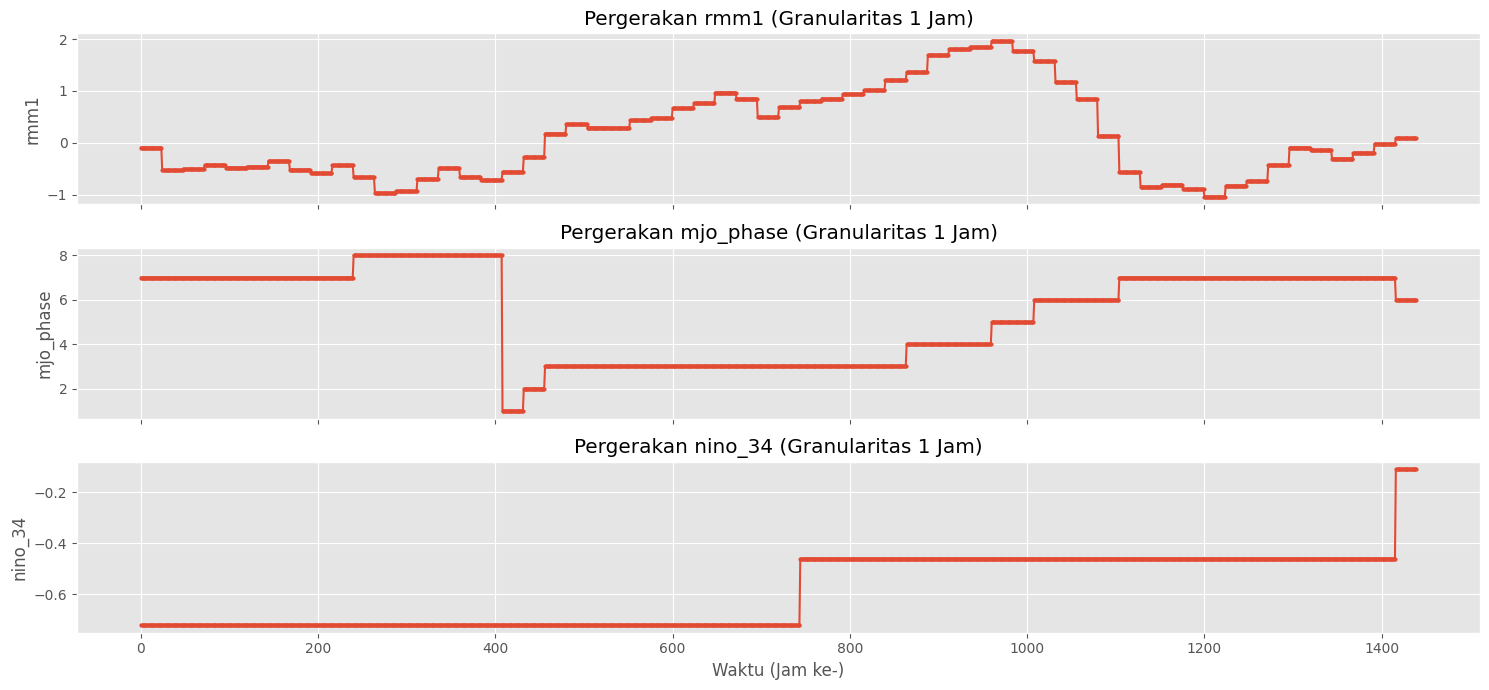

In [ ]:
macro_features = ['rmm1', 'mjo_phase', 'nino_34']
subset_env = df_env[df_env['nama_pos'] == pos_example].iloc[:int(0.75 * len(df_env[df_env['nama_pos'] == pos_example]))].reset_index(drop=True)

fig, axes = plt.subplots(3, 1, figsize=(15, 7), sharex=True)
for i, feat in enumerate(macro_features):
    axes[i].plot(subset_env.index, subset_env[feat], marker='o', markersize=2)
    axes[i].set_ylabel(feat)
    axes[i].set_title(f'Pergerakan {feat} (Granularitas 1 Jam)')

axes[-1].set_xlabel('Waktu (Jam ke-)')
plt.tight_layout()
plt.savefig('output_eda/plot_13.png', bbox_inches='tight', dpi=300)
plt.show()

Terlihat bahwa `nino_34` hanya berubah pada interval waktu yang cukup lama (bernilai konstan selama berhari-hari/berbulan-bulan). Memakai fitur *slow-varying* secara mentah (tanpa *lag* panjang atau agregasi bulanan) akan berisiko menjadi sumber representasi palsu bagi model mesin learning (model sekadar "menghafal" nilai konstan). 
Direkomendasikan fitur ini di-*drop* atau diturunkan menjadi fitur kategorik (misal fase nino/nina) secara global, alih-alih regressor titik per titik.

---
## Exploratory Data Analysis (EDA): Leakage & Konsistensi Temporal

Fokus EDA:
1. **Cek definisi window `rainfall_max_24h_mm`** - Backward-looking atau menyertakan data masa depan? Ini WAJIB dicek, karena kalau salah, model akan "curang" saat training tapi gagal total saat inference real.
2. **Overlap tanggal train vs test** - Pastikan split time-based (forecast ke depan), bukan random split.
3. **Granularitas climate index (MJO, Nino3.4)** - Real-time atau revised value? Climate index sering direvisi setelah kejadian, dan itu bisa jadi leakage halus yang sering kelewat.

### 1. Cek Window `rainfall_max_24h_mm` (Backward-looking vs Leakage)

In [ ]:
# Idenya: hitung ulang rolling max 24 jam secara manual (STRICT backward-looking, hanya pakai data <= t)
# lalu bandingkan dengan kolom rainfall_max_24h_mm yang sudah disediakan di dataset.
# Kalau nilainya cocok -> aman (backward-looking). Kalau provided value systematically berbeda -> indikasi
# window-nya menyertakan data masa depan (leakage) atau definisinya beda dari yang kita asumsikan.

pos_check = df_train['nama_pos'].unique()[0]
env_check = df_env[df_env['nama_pos'] == pos_check].copy().set_index('datetime').sort_index()

# Rolling max 24 jam manual, backward-looking (window waktu, hanya lihat ke belakang)
env_check['rainfall_max_24h_manual'] = env_check['rainfall_mm'].rolling('24h', min_periods=1).max()

compare = env_check[['rainfall_mm', 'rainfall_max_24h_mm', 'rainfall_max_24h_manual']].copy()
compare['diff'] = compare['rainfall_max_24h_mm'] - compare['rainfall_max_24h_manual']

print(f"Pos yang dicek: {pos_check}")
print("\nStatistik selisih (provided - manual backward rolling):")
display(compare['diff'].describe())

n_mismatch = (compare['diff'].abs() > 1e-6).sum()
pct_mismatch = n_mismatch / len(compare) * 100
print(f"\nJumlah baris yang TIDAK match dengan rolling backward manual: {n_mismatch} ({pct_mismatch:.2f}%)")

if pct_mismatch < 1:
    print(">> AMAN: rainfall_max_24h_mm konsisten dengan definisi backward-looking (rolling 24 jam ke belakang).")
else:
    print(">> WARNING: Ada mismatch signifikan! Cek apakah window rainfall_max_24h_mm menyertakan data masa depan")
    print("   (leakage) atau memakai definisi kalender/window yang berbeda dari asumsi kita.")

compare.head(30)

Pos yang dicek: Arjowinangun - Pacitan

Statistik selisih (provided - manual backward rolling):


count    29616.00000
mean        -0.00029
std          0.01156
min         -1.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          0.00000
Name: diff, dtype: float64


Jumlah baris yang TIDAK match dengan rolling backward manual: 32 (0.11%)
>> AMAN: rainfall_max_24h_mm konsisten dengan definisi backward-looking (rolling 24 jam ke belakang).


,rainfall_mm,rainfall_max_24h_mm,rainfall_max_24h_manual,diff
datetime,,,,
2023-01-01 00:00:00,0.0,0.0,0.0,0.0
2023-01-01 01:00:00,0.0,0.0,0.0,0.0
2023-01-01 02:00:00,0.0,0.0,0.0,0.0
2023-01-01 03:00:00,0.0,0.0,0.0,0.0
2023-01-01 04:00:00,0.0,0.0,0.0,0.0
2023-01-01 05:00:00,0.0,0.0,0.0,0.0
2023-01-01 06:00:00,0.0,0.0,0.0,0.0
2023-01-01 07:00:00,0.0,0.0,0.0,0.0
2023-01-01 08:00:00,0.0,0.0,0.0,0.0


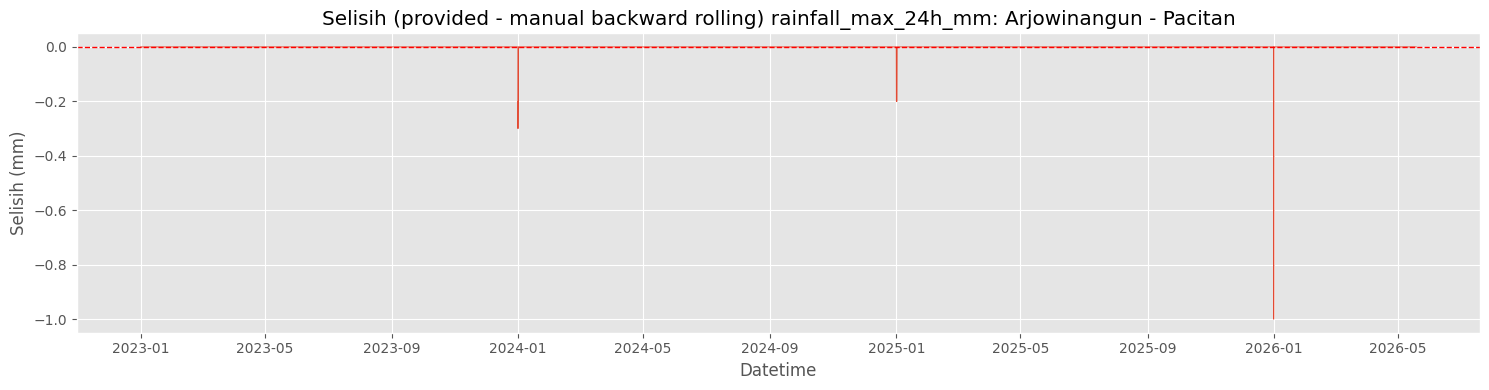

In [ ]:
# Visualisasi selisih sepanjang waktu — kalau mismatch terjadi random/kecil = OK, kalau sistematis & besar = red flag
plt.figure(figsize=(15, 4))
plt.plot(compare.index, compare['diff'], linewidth=0.7)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title(f'Selisih (provided - manual backward rolling) rainfall_max_24h_mm: {pos_check}')
plt.ylabel('Selisih (mm)')
plt.xlabel('Datetime')
plt.tight_layout()
plt.savefig('output_eda/plot_14.png', bbox_inches='tight', dpi=300)
plt.show()

### 2. Overlap Tanggal Train vs Test

In [ ]:
# Pastikan split time-based: test set seharusnya di masa depan relatif terhadap train, bukan random split
import os

test_path = '../test.csv'
if os.path.exists(test_path):
    df_test = pd.read_csv(test_path)

    # test.csv formatnya beda dari train.csv: cuma ada kolom 'id' = "datetime - nama_pos"
    # split cuma 1x di kemunculan " - " pertama, karena beberapa nama_pos JUGA mengandung " - "
    # (misal "Bojonegoro - Kali Kethek", "Kali Anyar - Kreteg Abang") -> split(n=1) aman karena
    # panjang format datetime-nya selalu fixed, jadi separator pertama pasti pemisah datetime|nama_pos
    id_split = df_test['id'].str.split(' - ', n=1, expand=True)
    df_test['datetime'] = pd.to_datetime(id_split[0])
    df_test['nama_pos'] = id_split[1]

    train_start, train_end = df_train['datetime'].min(), df_train['datetime'].max()
    test_start, test_end = df_test['datetime'].min(), df_test['datetime'].max()

    print(f"Rentang TRAIN : {train_start} s/d {train_end}")
    print(f"Rentang TEST  : {test_start} s/d {test_end}")

    overlap = df_test['datetime'].between(train_start, train_end).sum()
    print(f"\nJumlah baris TEST yang tanggalnya overlap dengan rentang TRAIN: {overlap} dari {len(df_test)} ({overlap/len(df_test)*100:.2f}%)")

    if test_start > train_end:
        print(">> AMAN: Split time-based murni. Test set 100% di masa depan relatif terhadap train.")
    elif overlap == 0:
        print(">> AMAN: Tidak ada overlap tanggal antara train dan test.")
    else:
        print(">> WARNING: Ada overlap tanggal! Kemungkinan split RANDOM, bukan time-based.")
        print("   Ini bisa menyebabkan data leakage saat membuat fitur lag/rolling (info masa depan bocor ke training).")

    if 'nama_pos' in df_test.columns:
        overlap_per_pos = df_test.groupby('nama_pos')['datetime'].agg(['min', 'max', 'count'])
        display(overlap_per_pos)
else:
    print(f"File {test_path} tidak ditemukan. Skip cek overlap train-test (pastikan test.csv ada di root folder).")

Rentang TRAIN : 2023-01-01 06:00:00 s/d 2025-09-18 18:00:00
Rentang TEST  : 2025-09-19 06:00:00 s/d 2026-05-18 18:00:00

Jumlah baris TEST yang tanggalnya overlap dengan rentang TRAIN: 0 dari 21780 (0.00%)
>> AMAN: Split time-based murni. Test set 100% di masa depan relatif terhadap train.


,min,max,count
nama_pos,,,
Arjowinangun - Pacitan,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Babat,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Badegan,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Bengkelolor,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Boboh Kali Lamong,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Bojonegoro - Kali Kethek,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Brangkal,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Cepu,2025-09-19 06:00:00,2026-05-18 18:00:00,726
Colo Weir,2025-09-19 06:00:00,2026-05-18 18:00:00,726


### 3. Granularitas & Indikasi Revisi pada Climate Index (MJO, Nino3.4)

In [ ]:
# Climate index seperti Nino3.4 biasanya dipublish BULANAN dan sering DIREVISI beberapa bulan setelah observasi asli
# (bukan real-time). Kalau dataset ini pakai versi revised, itu leakage halus: model "tahu" nilai final index
# sebelum index tsb benar-benar dipublikasi secara real-time saat itu.

climate_cols = [c for c in ['rmm1', 'rmm2', 'mjo_phase', 'mjo_amplitude', 'mjo_active', 'nino_34'] if c in df_env.columns]
env_climate = df_env[df_env['nama_pos'] == pos_check].copy().set_index('datetime').sort_index()

# Cek granularitas: berapa lama tiap fitur climate index bertahan konstan sebelum berubah nilai
print("Granularitas (median durasi nilai konstan) per fitur climate index:")
for col in climate_cols:
    vals = env_climate[col]
    change_points = vals.ne(vals.shift()).cumsum()
    durations = vals.groupby(change_points).size()
    median_hours = durations.median()
    print(f"  {col:15s}: median durasi konstan = {median_hours:.0f} jam (~{median_hours/24:.1f} hari)")

# Cek khusus nino_34: apakah berubah tepat di awal bulan (indikasi data monthly yang di-assign flat ke semua jam di bulan itu)
env_climate['bulan_tahun'] = env_climate.index.to_period('M')
nino_per_month = env_climate.groupby('bulan_tahun')['nino_34'].nunique()
print(f"\nJumlah bulan dengan nino_34 TIDAK konstan sepanjang bulan: {(nino_per_month > 1).sum()} dari {len(nino_per_month)} bulan")

print("""
>> CATATAN PENTING (tidak bisa divalidasi 100% cuma dari dataset ini, perlu cek ke sumber data NOAA/BOM):
   Nino3.4/ONI resmi biasanya baru dipublikasi ~1 bulan setelah bulan berjalan selesai, dan seringkali
   direvisi lagi beberapa bulan kemudian. Kalau nilai nino_34 di sini SUDAH tersedia sejak awal bulan
   berjalan (bukan delayed), kemungkinan besar ini pakai versi REVISED/final, bukan real-time operasional.
   -> Rekomendasi: kalau mau aman dari leakage, gunakan nino_34/RMM dengan LAG minimal 1-2 bulan saat
      feature engineering, jangan pakai value di bulan yang sama dengan waktu prediksi.
""")

Granularitas (median durasi nilai konstan) per fitur climate index:
  rmm1           : median durasi konstan = 24 jam (~1.0 hari)
  rmm2           : median durasi konstan = 24 jam (~1.0 hari)
  mjo_phase      : median durasi konstan = 72 jam (~3.0 hari)
  mjo_amplitude  : median durasi konstan = 24 jam (~1.0 hari)
  mjo_active     : median durasi konstan = 108 jam (~4.5 hari)
  nino_34        : median durasi konstan = 1 jam (~0.0 hari)

Jumlah bulan dengan nino_34 TIDAK konstan sepanjang bulan: 0 dari 41 bulan

>> CATATAN PENTING (tidak bisa divalidasi 100% cuma dari dataset ini, perlu cek ke sumber data NOAA/BOM):
   Nino3.4/ONI resmi biasanya baru dipublikasi ~1 bulan setelah bulan berjalan selesai, dan seringkali
   direvisi lagi beberapa bulan kemudian. Kalau nilai nino_34 di sini SUDAH tersedia sejak awal bulan
   berjalan (bukan delayed), kemungkinan besar ini pakai versi REVISED/final, bukan real-time operasional.
   -> Rekomendasi: kalau mau aman dari leakage, gunakan nino_34/R

---
## Exploratory Data Analysis (EDA): Spasial (Koordinat Pos & Topologi Sungai)

Fokus EDA:
1. **Plot 30 pos di peta** - Sebaran geografis pos pemantauan.
2. **Struktur hulu-hilir dari HydroRIVERS** (`NEXT_DOWN`, `MAIN_RIV`) - Fitur upstream-downstream antar pos, biasanya sangat prediktif untuk flood forecasting.
3. **Korelasi TMA vs jarak antar pos** - Validasi apakah asumsi topologi sungai kelihatan efeknya di data historis.

### 1. Plot 30 Pos di Peta (Lat/Lon)

Shape koordinat_pos: (30, 3)


,nama_pos,latitude,longitude
0,Ketonggo,-7.424100,111.449500
1,Sekayu,-7.865200,111.447900
2,Cepu,-7.148300,111.598600
3,Karanggeneng,-6.989600,112.368800
4,Bojonegoro - Kali Kethek,-7.136803,111.897763


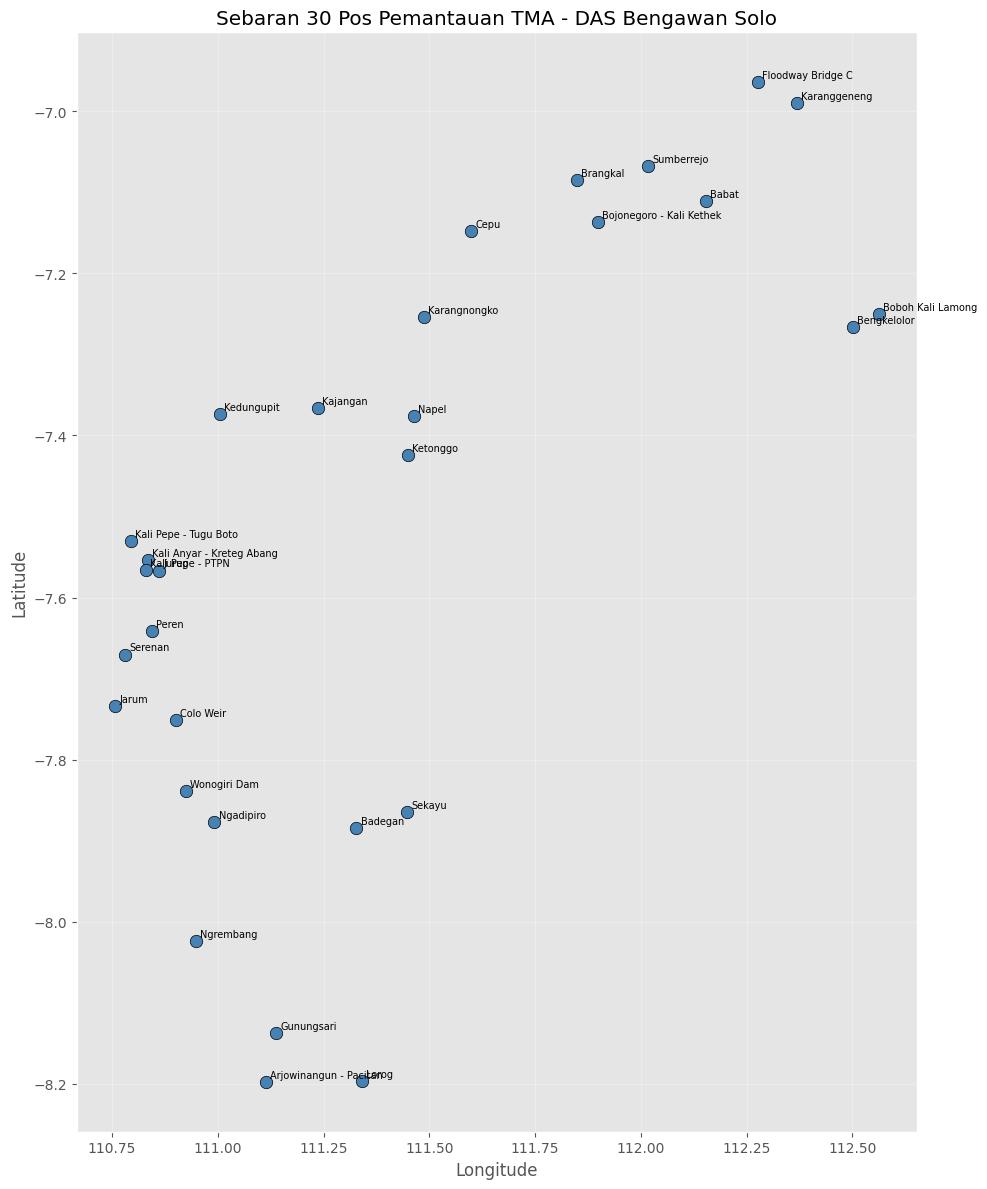

In [ ]:
df_koor = pd.read_csv('../data_pendukung/koordinat_pos.csv')
print("Shape koordinat_pos:", df_koor.shape)
display(df_koor.head())

plt.figure(figsize=(10, 12))
plt.scatter(df_koor['longitude'], df_koor['latitude'], s=80, c='steelblue', edgecolor='black', zorder=3)

for _, row in df_koor.iterrows():
    plt.annotate(row['nama_pos'], (row['longitude'], row['latitude']),
                 fontsize=7, xytext=(3, 3), textcoords='offset points')

plt.title('Sebaran 30 Pos Pemantauan TMA - DAS Bengawan Solo')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('output_eda/plot_15.png', bbox_inches='tight', dpi=300)
plt.show()

### 2. Struktur Hulu-Hilir dari HydroRIVERS

In [ ]:
# Snap tiap pos ke river reach terdekat, lalu ekstrak topologi (NEXT_DOWN, MAIN_RIV, jarak, urutan sungai)
# Kolom penting: NEXT_DOWN (reach di bawahnya), MAIN_RIV (ID reach paling hilir di basin yg sama),
# DIST_DN_KM (jarak ke muara), UPLAND_SKM (luas catchment di atas titik ini), ORD_STRA/ORD_FLOW (ordo sungai)

try:
    import geopandas as gpd
    from shapely.geometry import Point

    shp_path = '../data_pendukung/HydroRIVERS_v10_au_shp/HydroRIVERS_v10_au.shp'
    rivers = gpd.read_file(shp_path)
    print("Jumlah river reach dalam shapefile:", len(rivers))
    display(rivers.head(3))

    pos_gdf = gpd.GeoDataFrame(
        df_koor.copy(),
        geometry=[Point(xy) for xy in zip(df_koor['longitude'], df_koor['latitude'])],
        crs='EPSG:4326'
    )
    if rivers.crs != pos_gdf.crs:
        rivers = rivers.to_crs(pos_gdf.crs)

    # Snap tiap pos ke reach terdekat
    pos_snapped = gpd.sjoin_nearest(pos_gdf, rivers, how='left', distance_col='dist_to_reach_deg')

    cols_topo = ['nama_pos', 'latitude', 'longitude', 'HYRIV_ID', 'NEXT_DOWN', 'MAIN_RIV',
                 'LENGTH_KM', 'DIST_DN_KM', 'DIST_UP_KM', 'UPLAND_SKM', 'ORD_STRA', 'ORD_FLOW', 'dist_to_reach_deg']
    cols_topo = [c for c in cols_topo if c in pos_snapped.columns]
    pos_topo = pos_snapped[cols_topo].copy()

    print("\nHasil snapping pos ke river reach terdekat:")
    display(pos_topo)

    # Urutkan pos dari hulu (DIST_DN_KM besar) ke hilir (DIST_DN_KM kecil), dikelompokkan per basin (MAIN_RIV)
    print("\nUrutan pos dari HULU ke HILIR (berdasarkan DIST_DN_KM, dikelompokkan per basin MAIN_RIV):")
    display(pos_topo.sort_values(['MAIN_RIV', 'DIST_DN_KM'], ascending=[True, False]))

    # Simpan hasil ekstraksi topologi untuk dipakai di tahap feature engineering nanti
    pos_topo.to_csv('pos_topologi_sungai.csv', index=False)
    print("\n>> Disimpan ke 'pos_topologi_sungai.csv' untuk dipakai di tahap feature engineering (fitur upstream station).")

except ImportError:
    print("Library 'geopandas' belum terinstall. Jalankan: !pip install geopandas shapely")
except FileNotFoundError:
    print(f"Shapefile tidak ditemukan di path yang diharapkan: {shp_path}")
    print("Pastikan folder 'data_pendukung/HydroRIVERS_v10_au_shp/' berisi file .shp, .dbf, .shx, dll lengkap.")

Jumlah river reach dalam shapefile: 836472


,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,DIST_DN_KM,DIST_UP_KM,CATCH_SKM,UPLAND_SKM,ENDORHEIC,DIS_AV_CMS,ORD_STRA,ORD_CLAS,ORD_FLOW,HYBAS_L12,geometry
0,50000001,50000003,50000003,1.59,1.5,3.0,3.61,3.6,0,0.153,1,2,7,5120031120,"LINESTRING (121.8375 20.75, 121.84375 20.75625..."
1,50000002,50000003,50000003,5.04,1.3,7.9,16.66,16.7,0,0.678,1,1,7,5120031120,"LINESTRING (121.84375 20.79583, 121.84375 20.7..."
2,50000003,0,50000003,1.07,0.0,9.0,2.21,22.1,0,0.895,2,1,7,5120031120,"LINESTRING (121.84792 20.75208, 121.85208 20.7..."



Hasil snapping pos ke river reach terdekat:


,nama_pos,latitude,longitude,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,DIST_DN_KM,DIST_UP_KM,UPLAND_SKM,ORD_STRA,ORD_FLOW,dist_to_reach_deg
0,Ketonggo,-7.424100,111.449500,50400215,50399368,50387677,8.01,245.5,14.0,21.5,1,7,0.001183
1,Sekayu,-7.865200,111.447900,50411596,50411198,50387677,1.85,303.7,49.5,800.9,4,5,0.004183
2,Cepu,-7.148300,111.598600,50390791,50391195,50387677,2.04,194.2,233.1,10926.8,6,4,0.000683
3,Karanggeneng,-6.989600,112.368800,50385278,50385424,50387677,5.76,35.1,392.2,15087.4,6,4,0.000047
4,Bojonegoro - Kali Kethek,-7.136803,111.897763,50390371,50390651,50387677,5.37,134.7,292.6,12778.1,6,4,0.001387
5,Badegan,-7.884900,111.327500,50412167,50411880,50387677,3.99,315.8,34.5,276.7,4,6,0.000517
6,Lorog,-8.196982,111.341354,50418676,50419038,50419937,1.76,9.3,12.3,47.6,3,6,0.001033
7,Wonogiri Dam,-7.838796,110.925491,50411016,50410506,50387677,2.32,378.3,49.0,1344.7,4,5,0.001593
8,Kajangan,-7.365744,111.235721,50397516,50397660,50387677,0.92,271.6,155.6,5492.4,5,4,0.001161
9,Boboh Kali Lamong,-7.250400,112.562300,50393700,50393566,50392385,1.11,11.8,62.7,617.2,4,5,0.002483



Urutan pos dari HULU ke HILIR (berdasarkan DIST_DN_KM, dikelompokkan per basin MAIN_RIV):


,nama_pos,latitude,longitude,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,DIST_DN_KM,DIST_UP_KM,UPLAND_SKM,ORD_STRA,ORD_FLOW,dist_to_reach_deg
14,Ngrembang,-8.024400,110.948000,50415087,50414892,50387677,1.30,405.4,18.0,138.8,3,6,0.000990
12,Ngadipiro,-7.876715,110.991808,50411875,50411669,50387677,3.14,389.3,37.9,377.5,3,5,0.001113
7,Wonogiri Dam,-7.838796,110.925491,50411016,50410506,50387677,2.32,378.3,49.0,1344.7,4,5,0.001593
11,Colo Weir,-7.751307,110.901425,50408686,50408685,50387677,0.69,367.6,4.4,3.6,1,7,0.000658
24,Jarum,-7.733700,110.757100,50408345,50407816,50387677,2.88,356.0,61.6,638.1,4,5,0.011172
29,Serenan,-7.670500,110.780000,50406621,50406245,50387677,1.39,348.2,79.1,2477.8,5,5,0.001250
22,Peren,-7.641000,110.844800,50405918,50405917,50387677,1.84,346.7,17.5,30.8,2,6,0.006917
16,Kali Pepe - Tugu Boto,-7.530054,110.793742,50402906,50403203,50387677,7.94,339.7,12.2,24.9,2,7,0.007137
19,Kali Pepe - PTPN,-7.566376,110.830243,50404048,50404049,50387677,3.11,336.2,5.1,7.0,1,7,0.001793
23,Jurug,-7.566700,110.861000,50404050,50403550,50387677,4.49,333.6,7.3,11.3,1,7,0.000583



>> Disimpan ke 'pos_topologi_sungai.csv' untuk dipakai di tahap feature engineering (fitur upstream station).


### 3. Korelasi TMA vs Jarak Geografis Antar Pos

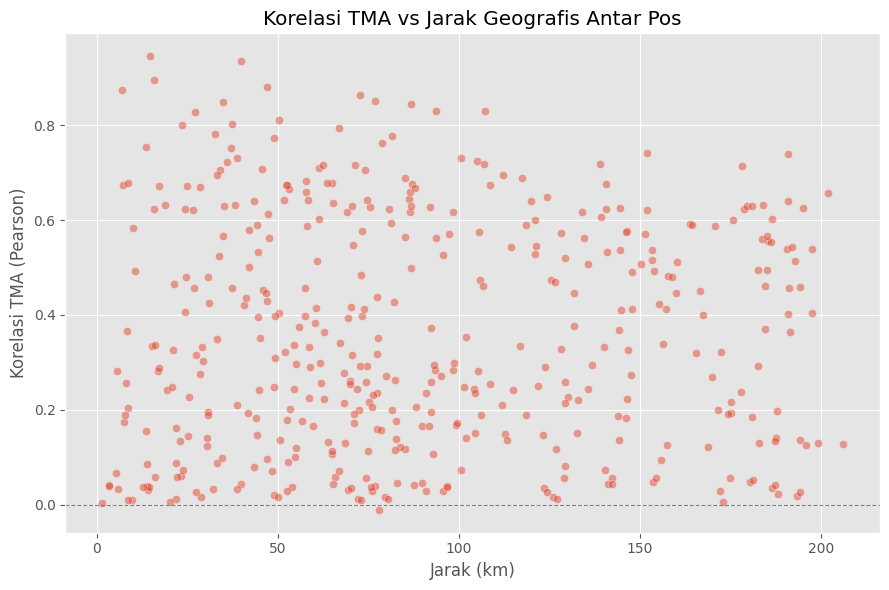

Korelasi antara jarak & korelasi-TMA: 0.015
(Idealnya NEGATIF: makin jauh jaraknya, makin lemah korelasi TMA-nya -> mengkonfirmasi efek topologi sungai)

Top 10 pasangan pos dengan korelasi TMA tertinggi (kandidat hulu-hilir searah):


,pos1,pos2,jarak_km,korelasi_tma
296,Jurug,Serenan,14.591603,0.946045
367,Karanggeneng,Sumberrejo,39.696323,0.936407
55,Babat,Sumberrejo,15.854607,0.894658
202,Cepu,Sumberrejo,47.114744,0.880309
84,Bengkelolor,Boboh Kali Lamong,6.913722,0.873942
295,Jurug,Sekayu,72.689837,0.864319
429,Sekayu,Serenan,76.704252,0.851211
194,Cepu,Ketonggo,34.798652,0.849398
191,Cepu,Karanggeneng,86.803952,0.845105
201,Cepu,Serenan,107.327576,0.831000


In [ ]:
# Menggunakan corr_matrix yang sudah dihitung di bagian target (Section: Perbandingan Pos Searah Hulu-Hilir)
# Idenya: kalau topologi sungai memang berpengaruh, pos yang berdekatan (searah sungai) harusnya
# punya korelasi TMA yang lebih tinggi dibanding pos yang jauh.

from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # km
    dlat, dlon = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return 2 * R * atan2(sqrt(a), sqrt(1 - a))

koor_idx = df_koor.set_index('nama_pos')
pos_list = corr_matrix.columns.tolist()

records = []
for i, p1 in enumerate(pos_list):
    for p2 in pos_list[i+1:]:
        if p1 in koor_idx.index and p2 in koor_idx.index:
            dist_km = haversine(koor_idx.loc[p1, 'latitude'], koor_idx.loc[p1, 'longitude'],
                                 koor_idx.loc[p2, 'latitude'], koor_idx.loc[p2, 'longitude'])
            records.append({'pos1': p1, 'pos2': p2, 'jarak_km': dist_km, 'korelasi_tma': corr_matrix.loc[p1, p2]})

dist_corr_df = pd.DataFrame(records)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=dist_corr_df, x='jarak_km', y='korelasi_tma', alpha=0.5)
plt.title('Korelasi TMA vs Jarak Geografis Antar Pos')
plt.xlabel('Jarak (km)')
plt.ylabel('Korelasi TMA (Pearson)')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('output_eda/plot_16.png', bbox_inches='tight', dpi=300)
plt.show()

corr_dist_r = dist_corr_df['jarak_km'].corr(dist_corr_df['korelasi_tma'])
print(f"Korelasi antara jarak & korelasi-TMA: {corr_dist_r:.3f}")
print("(Idealnya NEGATIF: makin jauh jaraknya, makin lemah korelasi TMA-nya -> mengkonfirmasi efek topologi sungai)")

print("\nTop 10 pasangan pos dengan korelasi TMA tertinggi (kandidat hulu-hilir searah):")
display(dist_corr_df.sort_values('korelasi_tma', ascending=False).head(10))

---
## Exploratory Data Analysis (EDA): Data Statis (`built_surface_m2`, `landcover_class`/`landcover_name`)

Fokus EDA:
1. **Konsistensi nilai per pos sepanjang waktu** - Apakah fitur ini benar-benar statis (bisa jadi fitur per-pos, bukan time-varying).
2. **Distribusi landcover per pos** - Menjelaskan perbedaan respons hidrologi antar pos (built-up = runoff cepat, tree cover = lebih lambat/terserap).

### 1. Cek Konsistensi Nilai Statis per Pos

In [ ]:
# Apakah built_surface_m2 & landcover benar-benar konstan sepanjang waktu untuk tiap pos?
static_check_cols = [c for c in ['built_surface_m2', 'landcover_class', 'landcover_name'] if c in df_env.columns]

nunique_per_pos = df_env.groupby('nama_pos')[static_check_cols].nunique()
print("Jumlah nilai unik per pos untuk tiap fitur (idealnya = 1 kalau benar-benar statis):")
display(nunique_per_pos)

if (nunique_per_pos.max() == 1).all():
    print("\n>> KONFIRMASI: Semua fitur statis (built_surface_m2, landcover) benar-benar konstan per pos.")
    print("   -> Bisa langsung dijadikan fitur per-pos (join sekali via nama_pos), TIDAK perlu dianggap time-varying feature.")
else:
    cols_not_static = nunique_per_pos.columns[(nunique_per_pos > 1).any()].tolist()
    print(f"\n>> WARNING: Fitur berikut TERNYATA berubah dalam waktu untuk sebagian pos: {cols_not_static}")
    print("   -> Perlu ditelusuri lebih lanjut, kemungkinan ada update data periodik (misal landcover berubah karena deforestasi/pembangunan).")

Jumlah nilai unik per pos untuk tiap fitur (idealnya = 1 kalau benar-benar statis):


,built_surface_m2,landcover_class,landcover_name
nama_pos,,,
Arjowinangun - Pacitan,1,1,1
Babat,1,1,1
Badegan,1,1,1
Bengkelolor,1,1,1
Boboh Kali Lamong,1,1,1
Bojonegoro - Kali Kethek,1,1,1
Brangkal,1,1,1
Cepu,1,1,1
Colo Weir,1,1,1



>> KONFIRMASI: Semua fitur statis (built_surface_m2, landcover) benar-benar konstan per pos.
   -> Bisa langsung dijadikan fitur per-pos (join sekali via nama_pos), TIDAK perlu dianggap time-varying feature.


### 2. Distribusi Landcover per Pos

Landcover dominan per pos:


,nama_pos,landcover_dominan
0,Arjowinangun - Pacitan,Tree cover
1,Babat,Tree cover
2,Badegan,Tree cover
3,Bengkelolor,Cropland
4,Boboh Kali Lamong,Tree cover
5,Bojonegoro - Kali Kethek,Permanent water bodies
6,Brangkal,Tree cover
7,Cepu,Permanent water bodies
8,Colo Weir,Built-up
9,Floodway Bridge C,Permanent water bodies


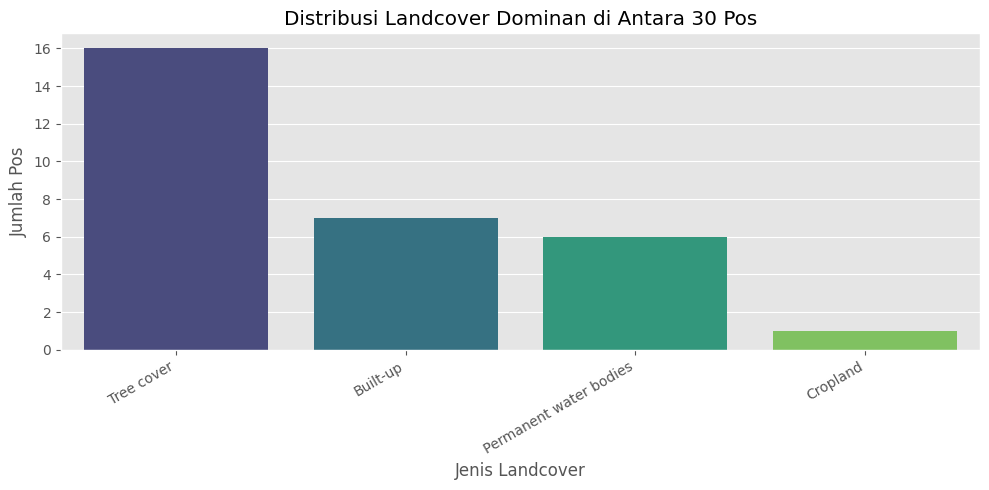


Overview fitur statis per pos (landcover dominan + rata-rata built_surface_m2):


,nama_pos,landcover_dominan,built_surface_m2
15,Kali Pepe - PTPN,Built-up,4729.0
14,Kali Anyar - Kreteg Abang,Built-up,2960.0
0,Arjowinangun - Pacitan,Tree cover,2419.0
16,Kali Pepe - Tugu Boto,Built-up,2122.0
11,Jarum,Tree cover,1427.0
10,Gunungsari,Tree cover,1173.0
2,Badegan,Tree cover,1149.0
12,Jurug,Built-up,751.0
8,Colo Weir,Built-up,600.0
6,Brangkal,Tree cover,514.0



>> INSIGHT: Pos dengan built_surface_m2 tinggi & landcover 'Built-up'/'Cropland' cenderung punya
   respons hidrologi lebih CEPAT terhadap hujan (runoff langsung, sedikit infiltrasi), sementara pos
   dengan landcover 'Tree cover' cenderung punya respons lebih LAMBAT/smooth (air terserap dulu ke
   tanah sebelum masuk sungai). Ini bisa jadi justifikasi fisik untuk menentukan window lag feature
   yang berbeda per karakteristik pos.
        


In [ ]:
if 'landcover_name' in df_env.columns:
    landcover_per_pos = df_env.groupby('nama_pos')['landcover_name'].agg(lambda x: x.mode()[0]).reset_index()
    landcover_per_pos.columns = ['nama_pos', 'landcover_dominan']

    print("Landcover dominan per pos:")
    display(landcover_per_pos)

    plt.figure(figsize=(10, 5))
    landcover_counts = landcover_per_pos['landcover_dominan'].value_counts()
    sns.barplot(x=landcover_counts.index, y=landcover_counts.values, palette='viridis')
    plt.title('Distribusi Landcover Dominan di Antara 30 Pos')
    plt.xlabel('Jenis Landcover')
    plt.ylabel('Jumlah Pos')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
plt.savefig('output_eda/plot_17.png', bbox_inches='tight', dpi=300)
    plt.show()

    # Gabungkan dengan built_surface_m2 rata-rata per pos untuk overview lengkap
    if 'built_surface_m2' in df_env.columns:
        built_per_pos = df_env.groupby('nama_pos')['built_surface_m2'].mean().reset_index()
        overview_statis = landcover_per_pos.merge(built_per_pos, on='nama_pos')
        print("\nOverview fitur statis per pos (landcover dominan + rata-rata built_surface_m2):")
        display(overview_statis.sort_values('built_surface_m2', ascending=False))

        print("""
>> INSIGHT: Pos dengan built_surface_m2 tinggi & landcover 'Built-up'/'Cropland' cenderung punya
   respons hidrologi lebih CEPAT terhadap hujan (runoff langsung, sedikit infiltrasi), sementara pos
   dengan landcover 'Tree cover' cenderung punya respons lebih LAMBAT/smooth (air terserap dulu ke
   tanah sebelum masuk sungai). Ini bisa jadi justifikasi fisik untuk menentukan window lag feature
   yang berbeda per karakteristik pos.
        """)
else:
    print("Kolom 'landcover_name' tidak ditemukan di df_env.")

### 7. Pengecekan Overlap Train dan Test
Kita perlu memastikan pembagian (split) data adalah berbasis waktu (time-based), di mana data uji (test) seluruhnya berada di masa depan dari data latih (train). Hal ini penting untuk menghindari *data leakage*.

In [ ]:
import os

test_path = '../test.csv'
if os.path.exists(test_path):
    df_test = pd.read_csv(test_path)
    
    # Ekstrak datetime dan nama_pos dari kolom id (format test.csv ternyata adalah: 'datetime - nama_pos')
    df_test['datetime'] = df_test['id'].str.split(' - ').str[0]
    df_test['datetime'] = pd.to_datetime(df_test['datetime'])
    df_test['nama_pos'] = df_test['id'].str.split(' - ', n=1).str[1]

    train_start, train_end = df_train['datetime'].min(), df_train['datetime'].max()
    test_start, test_end = df_test['datetime'].min(), df_test['datetime'].max()

    print(f"Rentang TRAIN : {train_start} s/d {train_end}")
    print(f"Rentang TEST  : {test_start} s/d {test_end}")

    overlap = df_test['datetime'].between(train_start, train_end).sum()
    print(f"\nJumlah baris TEST yang tanggalnya overlap dengan rentang TRAIN: {overlap} dari {len(df_test)} ({overlap/len(df_test)*100:.2f}%)")

    if test_start > train_end:
        print(">> AMAN: Split time-based murni. Test set 100% di masa depan relatif terhadap train.")
    elif overlap == 0:
        print(">> AMAN: Tidak ada overlap tanggal antara train dan test.")
    else:
        print(">> WARNING: Ada overlap tanggal! Kemungkinan split RANDOM, bukan time-based.")
        print("   Ini bisa menyebabkan data leakage saat membuat fitur lag/rolling (info masa depan bocor ke training).")

    # Cek juga rentang tanggal test per pos
    if 'nama_pos' in df_test.columns:
        overlap_per_pos = df_test.groupby('nama_pos')['datetime'].agg(['min', 'max', 'count'])
        display(overlap_per_pos.head(10))
else:
    print(f"File {test_path} tidak ditemukan. Skip cek overlap train-test.")

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Gabungkan df_train dengan data lingkungan untuk cek hujan saat spike
# Identifikasi spike sederhana: TMA > mean + 5*std per pos
outliers_check = []
for pos in df_train['nama_pos'].unique():
    pos_data = df_train[df_train['nama_pos'] == pos].copy()
    mean_val = pos_data['tma_mdpl'].mean()
    std_val = pos_data['tma_mdpl'].std()
    
    # Ambil data yang > 5 standard deviation (ekstrem spike)
    spikes = pos_data[pos_data['tma_mdpl'] > mean_val + 5 * std_val].copy()
    
    if not spikes.empty:
        # Cek curah hujan di data lingkungan pada jam yang sama atau 24 jam sebelumnya
        env_pos = df_env[df_env['nama_pos'] == pos].set_index('datetime')
        for idx, row in spikes.iterrows():
            spike_time = row['datetime']
            # Ambil akumulasi hujan 24 jam sebelum spike
            # Hindari KeyError dengan mengecek apakah range indeks tersebut ada
            if not env_pos.empty:
                try:
                    rain_24h = env_pos.loc[spike_time - pd.Timedelta(hours=24) : spike_time, 'rainfall_mm'].sum()
                except Exception:
                    rain_24h = np.nan
            else:
                rain_24h = np.nan
            
            outliers_check.append({
                'nama_pos': pos,
                'datetime': spike_time,
                'tma_spike_mdpl': row['tma_mdpl'],
                'tma_mean_pos': mean_val,
                'rain_24h_before_mm': rain_24h
            })

df_spikes = pd.DataFrame(outliers_check)
if not df_spikes.empty:
    print("Hasil Validasi Empiris (TMA Spike vs Curah Hujan 24 Jam):")
    display(df_spikes.sort_values('tma_spike_mdpl', ascending=False).head(15))
    print("Kesimpulan: Jika rain_24h_before_mm = 0.0 pada saat spike tinggi, ini 100% SENSOR ERROR.")
    
    # Plot detrending untuk Musiman
    print("\n================\nPlot Detrending Musiman:\n")
    pos_musiman = df_train['nama_pos'].unique()[0]
    data_musiman = df_train[df_train['nama_pos'] == pos_musiman].set_index('datetime').copy()
    data_musiman['rolling_90d'] = data_musiman['tma_mdpl'].rolling(window=4*90, min_periods=1).mean() # 4 step per hari * 90
    data_musiman['detrended'] = data_musiman['tma_mdpl'] - data_musiman['rolling_90d']
    data_musiman['bulan'] = data_musiman.index.month
    
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=data_musiman, x='bulan', y='detrended')
    plt.title(f'Musiman TMA (Detrended) per Bulan - Pos: {pos_musiman}')
    plt.ylabel('TMA Detrended (Fluktuasi dari Rata-rata)')
    plt.xlabel('Bulan')
    
    os.makedirs('output_eda', exist_ok=True)
    plt.savefig('output_eda/plot_detrended_musiman.png', bbox_inches='tight', dpi=300)
    plt.show()
else:
    print("Tidak ditemukan spike yang melebihi 5 Standard Deviation.")